# Módulo 3 — Extracción de Características, Textura y Dinámica Temporal
**PupilTrack — PSIB, ITBA (2do Q 2026) — Grupo 5**

- **3.1:** descriptores morfométricos y de textura (primer orden y GLCM) sobre la ROI segmentada, con frames reales del registro A1.
- **3.2:** procesamiento de los 4 registros completos (A1, A2: contracción; B1, B2: redilatación), curvas temporales, parámetros fisiológicos, variabilidad entre registros, artefactos y validación contra la medición manual (MAE/RMSE).

In [1]:
REGISTROS = {"A1": ("../data/A1.mov", "A"), "A2": ("../data/A2.mov", "A"),
             "B1": ("../data/B1.mov", "B"), "B2": ("../data/B2.mov", "B")}
FRAMES_31 = {"penumbra": ("A1", 331), "con luz": ("A1", 700)}   # frames para 3.1
NIVELES_GLCM = 32

## Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pupiltrack import acquisition as acq
from pupiltrack import preprocessing as pp
from pupiltrack import filtering as filt
from pupiltrack import edges_frequency as ef
from pupiltrack import segmentation as seg
from pupiltrack import morphology as morf
from pupiltrack import texture as tex
from pupiltrack import temporal as tmp
from pupiltrack import compression as comp

np.random.seed(0)
pd.set_option("display.width", 200)

def mostrar_varias(imagenes, titulos, cmap="gray", ancho=3.2, filas=1):
    cols = int(np.ceil(len(imagenes) / filas))
    fig, ax = plt.subplots(filas, cols, figsize=(ancho * cols, ancho * filas))
    ax = np.atleast_1d(ax).ravel()
    for a, im, t in zip(ax, imagenes, titulos):
        a.imshow(im if im.ndim == 3 else im, cmap=None if im.ndim == 3 else cmap)
        a.set_title(t, fontsize=9); a.axis("off")
    for a in ax[len(imagenes):]: a.axis("off")
    plt.tight_layout(); plt.show()

def generar_ojo_sintetico(size=300):
    img = np.full((size, size, 3), 230, dtype=np.uint8)
    centro = (size // 2, size // 2)
    cv2.circle(img, centro, 110, (180, 200, 210), -1)
    cv2.circle(img, centro, 70, (90, 60, 40), -1)
    cv2.circle(img, centro, 30, (10, 10, 10), -1)
    cv2.circle(img, (centro[0] + 12, centro[1] - 12), 6, (255, 255, 255), -1)
    return img
from pupiltrack import evaluacion as ev
from pupiltrack.config import cargar_config

## 3.1 — Descriptores morfométricos (forma)
Segmentación con el método del pipeline (watershed con marcadores + elipse sobre el borde visible), en un frame en penumbra y otro con luz.

,area_px,perimetro_px,centroide_x,centroide_y,circularidad,excentricidad,diametro_equivalente_px
frame,,,,,,,
penumbra,4399.0,245.966,126.953,119.462,0.914,0.287,74.840
con luz,2335.0,178.267,97.366,93.096,0.923,0.264,54.525


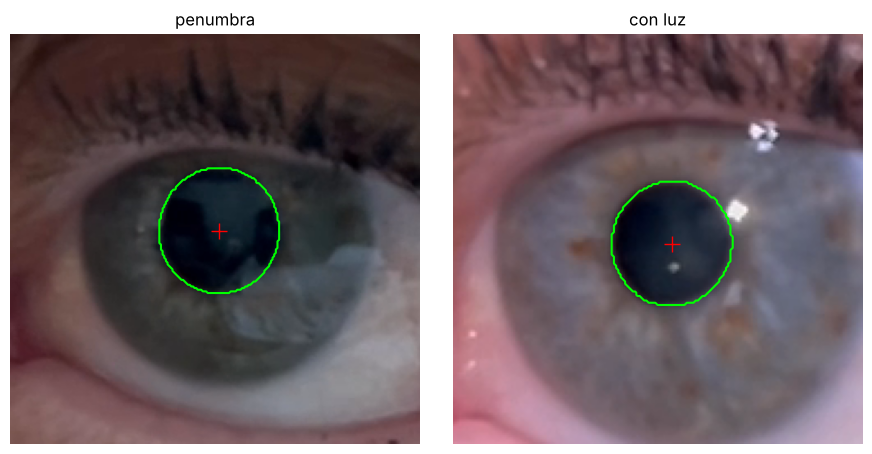

In [3]:
datos31 = {}
for nombre, (reg, i) in FRAMES_31.items():
    ruta = REGISTROS[reg][0]
    if not os.path.exists(ruta):
        print(f"Falta {ruta}"); continue
    fr = ev.leer_frame(ruta, i)
    roi_g, (x0, y0), c, r = ev.roi_automatica_pupila(fr)
    roi_c = fr[y0:y0 + roi_g.shape[0], x0:x0 + roi_g.shape[1]]
    mascara = tmp.refinar_borde_watershed(roi_g, c, r)
    datos31[nombre] = dict(roi_c=roi_c, roi_g=roi_g, mascara=mascara, c=c, r=r)

filas = []
for nombre, d in datos31.items():
    desc = morf.descriptores_morfometricos(d["mascara"])
    desc["diametro_equivalente_px"] = 2 * np.sqrt(desc["area_px"] / np.pi)
    filas.append({"frame": nombre, **{k: round(float(v), 3) for k, v in desc.items()}})
display(pd.DataFrame(filas).set_index("frame"))

fig, ax = plt.subplots(1, len(datos31), figsize=(4.5 * len(datos31), 4.5))
for a, (nombre, d) in zip(np.atleast_1d(ax), datos31.items()):
    a.imshow(cv2.cvtColor(d["roi_c"], cv2.COLOR_BGR2RGB)); a.contour(d["mascara"], [127], colors="lime")
    desc = morf.descriptores_morfometricos(d["mascara"])
    a.plot(desc["centroide_x"], desc["centroide_y"], "r+", ms=12); a.set_title(nombre); a.axis("off")
plt.tight_layout(); plt.show()

**Análisis.**
- La **circularidad** (4πA/P²) está cerca de 1 en los dos casos: la pupila es casi un círculo. Con luz es apenas más regular, porque el esfínter contraído deja un borde más nítido y sin la "mordida" del velo del reflejo.
- La **excentricidad** baja indica una elipse casi circular. El pequeño alargamiento viene de la mirada levemente oblicua respecto de la cámara.
- El **área** cae a menos de la mitad entre penumbra y luz: es el reflejo fotomotor que se cuantifica en 3.2.

## 3.1 — Textura de primer orden por canal (R, G, B)
Se calcula sobre la ROI completa (pupila + iris) y sobre una **región solo de iris** (anillo entre 1,3 y 2,2 radios pupilares, sin reflejo), que es la que describe el estroma iridiano. La ROI se cuantiza a 32 y 64 niveles para comparar.

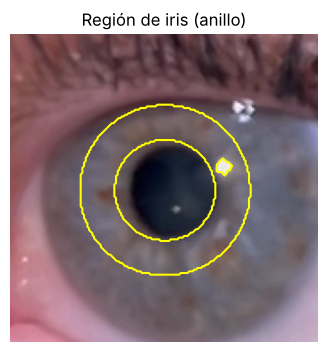

media  desvio  entropia  asimetria
región        canal                                      
ROI completa  R      108.397  38.781     3.975      0.115
              G       86.632  30.375     3.841      0.051
              B       96.365  33.169     4.031      0.433
Iris (anillo) R      104.226  14.214     2.705     -0.272
              G       92.890  14.864     2.826      0.211
              B       99.729  16.862     3.079      0.171

Efecto de la cuantización sobre la entropía (iris, bits):


niveles,32,64,256
canal,,,
B,3.079,4.061,6.040
G,2.826,3.817,5.785
R,2.705,3.678,5.656


In [4]:
d = datos31.get("con luz") or next(iter(datos31.values()))
roi_c, c, r = d["roi_c"], d["c"], d["r"]
yy, xx = np.indices(roi_c.shape[:2])
dist = np.hypot(xx - c[0], yy - c[1])
anillo = (dist >= 1.3 * r) & (dist <= 2.2 * r) & (cv2.cvtColor(roi_c, cv2.COLOR_BGR2GRAY) < 200)
plt.figure(figsize=(4, 4)); plt.imshow(cv2.cvtColor(roi_c, cv2.COLOR_BGR2RGB)); plt.contour(anillo, [0.5], colors="yellow"); plt.title("Región de iris (anillo)"); plt.axis("off"); plt.show()

def primer_orden_en(img_bgr, mascara=None):
    out = {}
    for nombre, idx in [("R", 2), ("G", 1), ("B", 0)]:
        canal = img_bgr[:, :, idx]
        vals = canal[mascara] if mascara is not None else canal.ravel()
        out[nombre] = tex.textura_primer_orden(vals.reshape(-1, 1))
    return out

filas = []
for region, m in [("ROI completa", None), ("Iris (anillo)", anillo)]:
    for niveles in (256, 64, 32):
        paso = 256 // niveles
        img_q = (roi_c // paso) * paso
        for canal, v in primer_orden_en(img_q, m).items():
            filas.append({"región": region, "niveles": niveles, "canal": canal, **v})
po = pd.DataFrame(filas)
display(po[po["niveles"] == 32].set_index(["región", "canal"]).drop(columns="niveles"))
print("Efecto de la cuantización sobre la entropía (iris, bits):")
display(po[po["región"] == "Iris (anillo)"].pivot(index="canal", columns="niveles", values="entropia"))

## 3.1 — Textura de segundo orden (GLCM)
GLCM cuantizada a 32 niveles, distancia 1, en las 4 direcciones (0°, 45°, 90° y 135°), simétrica y normalizada. Se extraen el contraste, la homogeneidad, la energía y la correlación (promedio de las 4 direcciones), por canal. Para el estroma se usa un **parche cuadrado de iris** debajo de la pupila (la GLCM necesita una región rectangular).

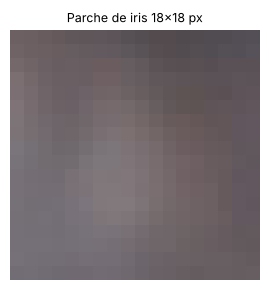

contrast  homogeneity  energy  correlation
región         canal                                            
ROI completa   R        0.7091       0.8046  0.2237       0.9848
               G        0.6412       0.8219  0.2306       0.9776
               B        0.6885       0.8028  0.1935       0.9798
Parche de iris R        0.3855       0.8238  0.3145       0.9088
               G        0.3756       0.8163  0.2984       0.9155
               B        0.3560       0.8282  0.3071       0.9253

ROI completa: canal con mayor contraste GLCM = R | menor homogeneidad = B | menor energía = B
Parche de iris: canal con mayor contraste GLCM = R | menor homogeneidad = G | menor energía = G


In [5]:
lado = int(0.8 * r)
py0, px0 = int(c[1] + 1.35 * r), int(c[0] - lado / 2)
parche = roi_c[py0:py0 + lado, px0:px0 + lado]
mostrar_varias([cv2.cvtColor(parche, cv2.COLOR_BGR2RGB)], [f"Parche de iris {lado}x{lado} px"], ancho=3)

filas = []
for region, img in [("ROI completa", roi_c), ("Parche de iris", parche)]:
    for canal, at in tex.textura_glcm_rgb(img, niveles=NIVELES_GLCM).items():
        filas.append({"región": region, "canal": canal, **at})
glcm = pd.DataFrame(filas).set_index(["región", "canal"])
display(glcm)
for region in ["ROI completa", "Parche de iris"]:
    sub = glcm.loc[region]
    print(f"{region}: canal con mayor contraste GLCM = {sub['contrast'].idxmax()} | menor homogeneidad = {sub['homogeneity'].idxmin()} | menor energía = {sub['energy'].idxmin()}")

**¿Qué canal aporta mayor riqueza textural del estroma iridiano?**
- En la **GLCM**, el canal **R** tiene el mayor **contraste**, tanto en la ROI completa (0,71, contra 0,64 de G y 0,69 de B) como en el parche de iris (0,386, contra 0,376 y 0,356): es el que tiene más variación de intensidad entre píxeles vecinos, es decir, más textura local. Las diferencias entre canales son chicas (alrededor del 8 %), algo esperable en un iris gris azulado con poca pigmentación.
- En **primer orden**, el canal **B** tiene el mayor desvío y la mayor entropía en el anillo de iris (16,9 y 3,08 bits a 32 niveles). Pero en la GLCM del parche, B es el **más homogéneo** y el de menor contraste: su variabilidad es más global (gradientes suaves y ruido del sensor, que en el azul es mayor) que estructura fina del estroma.
- La **correlación** GLCM es alta en los tres canales (mayor a 0,9): la intensidad varía en forma suave y continua en el espacio. La **energía** baja indica una textura no uniforme.
- **Conclusión:** para describir la textura del estroma conviene el canal **R** (mayor contraste local en la GLCM). Coincide con el Módulo 1, donde R también daba el mejor contraste pupila/iris en este ojo.
- **Cuantización:** pasar de 256 a 64 y a 32 niveles baja la entropía unos 2 y 3 bits respectivamente (por ejemplo, en R: 5,66 → 3,68 → 2,71), pero conserva el orden entre canales. Por eso cuantizar a 32 niveles para la GLCM no cambia la conclusión y hace la matriz más estable (32×32 en vez de 256×256).

## 3.2 — Procesamiento en video y curva temporal fisiológica
Se corre el pipeline completo (el mismo que `run_pipeline.py`) sobre los 4 registros.

In [6]:
cfg_base = cargar_config("../config.yaml")
series, params = {}, {}
for nombre, (ruta, tipo) in REGISTROS.items():
    if not os.path.exists(ruta):
        print(f"Falta {ruta}: se saltea"); continue
    cfg = {k: dict(v) if isinstance(v, dict) else v for k, v in cfg_base.items()}
    cfg["video"] = dict(cfg_base["video"], path=ruta, tipo=tipo)
    df, fps, _ = tmp.procesar_video(cfg)
    series[nombre] = df
    params[nombre] = tmp.calcular_parametros_fisiologicos(df, fps, tipo=tipo)
    print(f"{nombre}: {len(df)} frames a {fps:.2f} fps | frames válidos {100 * df['valido'].mean():.1f} %")
tabla = pd.DataFrame(params).T
cols = ["tipo_inferido", "t_estimulo_s", "diametro_basal", "diametro_extremo", "amplitud", "amplitud_pct",
        "latencia_s", "velocidad_constriccion", "velocidad_redilatacion", "frames_validos_pct"]
display(tabla[cols])

A1: 1494 frames a 59.96 fps | frames válidos 92.4 %


A2: 1317 frames a 59.96 fps | frames válidos 88.3 %


B1: 1354 frames a 59.96 fps | frames válidos 95.1 %


B2: 1522 frames a 59.96 fps | frames válidos 87.6 %


,tipo_inferido,t_estimulo_s,diametro_basal,diametro_extremo,amplitud,amplitud_pct,latencia_s,velocidad_constriccion,velocidad_redilatacion,frames_validos_pct
A1,A,6.421,75.444,53.434,22.011,29.17,0.233,41.084,12.838,92.4
A2,A,6.337,68.389,59.514,8.875,12.98,0.567,56.818,13.335,88.3
B1,B,6.104,56.552,67.529,10.977,19.41,0.2,NaN,11.117,95.1
B2,B,6.438,56.02,66.642,10.623,18.96,0.534,NaN,19.245,87.6


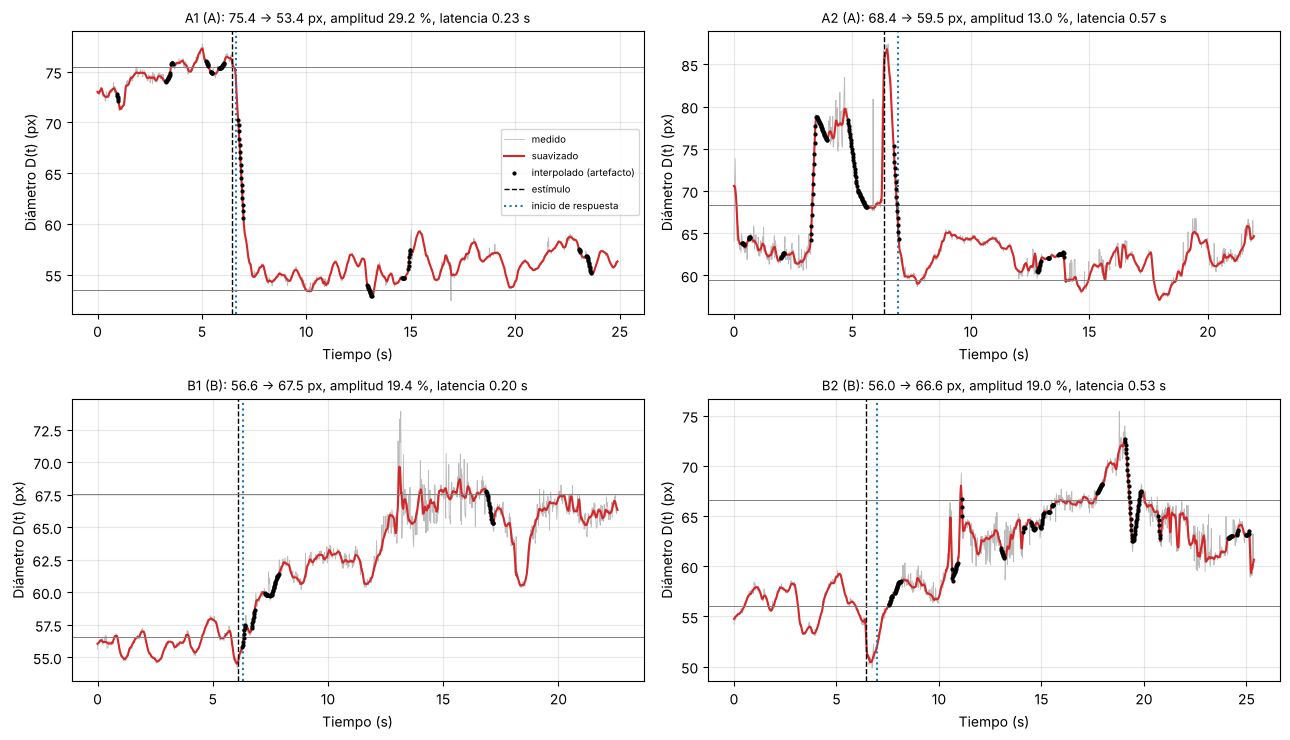

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (nombre, df) in zip(axs.ravel(), series.items()):
    p = params[nombre]
    d = tmp._suavizar(df["diametro_px"], 1 / df["tiempo_s"].diff().median())
    ax.plot(df["tiempo_s"], df["diametro_px"], c="#bbb", lw=.6, label="medido")
    ax.plot(df["tiempo_s"], d, c="tab:red", lw=1.5, label="suavizado")
    inv = ~df["valido"]
    ax.scatter(df["tiempo_s"][inv], d[inv], s=4, c="k", zorder=3, label="interpolado (artefacto)")
    ax.axvline(p["t_estimulo_s"], ls="--", c="k", lw=1, label="estímulo")
    ax.axvline(p["t_estimulo_s"] + p["latencia_s"], ls=":", c="tab:blue", lw=1.5, label="inicio de respuesta")
    ax.axhline(p["diametro_basal"], c="gray", lw=.7); ax.axhline(p["diametro_extremo"], c="gray", lw=.7)
    ax.set_title(f"{nombre} ({p['tipo_inferido']}): {p['diametro_basal']:.1f} → {p['diametro_extremo']:.1f} px, "
                 f"amplitud {p['amplitud_pct']:.1f} %, latencia {p['latencia_s']:.2f} s", fontsize=9.5)
    ax.set_xlabel("Tiempo (s)"); ax.set_ylabel("Diámetro D(t) (px)"); ax.grid(alpha=.3)
axs[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Parámetros.**
- **Latencia:** desde el estímulo (detectado automáticamente por el escalón de brillo del video) hasta que el diámetro se aparta del basal más que max(10 % de la amplitud, 2 × ruido basal).
- **Amplitud:** diferencia entre el diámetro basal (mediana del último segundo antes del estímulo) y el extremo: el mínimo en los 5 s posteriores en A, y el percentil 90 post-estímulo en B (la redilatación termina en una meseta lenta).
- **Velocidades:** máximo de |dD/dt| sobre la curva suavizada (mediana + Savitzky-Golay), en la fase de constricción o de redilatación.

### Variabilidad entre registros (latencia y amplitud)

In [8]:
num = ["diametro_basal", "diametro_extremo", "amplitud", "amplitud_pct", "latencia_s", "velocidad_constriccion", "velocidad_redilatacion"]
t = tabla.copy(); t[num] = t[num].astype(float)
var = []
for tipo, g in t.groupby("tipo_inferido"):
    for est, f in [("media", g[num].mean()), ("desvío", g[num].std(ddof=1)), ("CV %", 100 * g[num].std(ddof=1) / g[num].mean())]:
        var.append({"registro": f"{tipo} {est}", **f.round(3).to_dict()})
variabilidad = pd.DataFrame(var).set_index("registro")
display(variabilidad[["amplitud", "amplitud_pct", "latencia_s", "velocidad_constriccion", "velocidad_redilatacion"]])

,amplitud,amplitud_pct,latencia_s,velocidad_constriccion,velocidad_redilatacion
registro,,,,,
A media,15.443,21.075,0.400,48.951,13.086
A desvío,9.289,11.448,0.236,11.126,0.351
A CV %,60.147,54.321,59.043,22.728,2.685
B media,10.800,19.185,0.367,NaN,15.181
B desvío,0.250,0.318,0.236,NaN,5.747
B CV %,2.318,1.659,64.352,NaN,37.859


**Variabilidad entre registros.**
- **Amplitud:** los registros **B** son muy reproducibles (19,4 % y 19,0 %, con un CV de **1,7 %**). Los **A** difieren mucho (29,2 % y 13,0 %, con un CV del **54 %**). La diferencia es real y no un error de medición (lo verificamos midiendo a mano): en A2 la "penumbra" inicial era más clara, la pupila arrancó más cerrada (68 px contra 75 px en A1) y tenía menos margen para contraerse. La amplitud del reflejo depende mucho del nivel de adaptación inicial, así que el protocolo de oscuridad tiene que estar estandarizado.
- **Latencia:** A1 y B1 dan valores fisiológicos típicos (0,23 s y 0,20 s). A2 (0,57 s) y B2 (0,53 s) son más largas por artefactos justo en el estímulo: en A2, durante ~0,5 s del flash, el cambio brusco de iluminación hace que el borde oscuro del iris se sume a la medición; en B2, la pupila "baja" un instante al apagarse la luz (el ojo se entrecierra con el cambio). Por eso el CV de la latencia es alto (~60 %). La latencia de A2 debe tomarse con reserva.
- **Velocidades:** la constricción (A: 49 ± 11 px/s) es unas **3–4 veces más rápida** que la redilatación (A y B: 13–19 px/s). Es el comportamiento esperado: la constricción la produce el esfínter (vía parasimpática, rápida) y la redilatación es una recuperación más lenta (relajación del esfínter y acción del dilatador, vía simpática).

## 3.2 — Artefactos: fuentes y método de filtrado/interpolación
Fuentes de artefactos encontradas en los registros y cómo las maneja `pupiltrack/temporal.py`:

| Artefacto | Efecto en la medición | Método implementado |
|---|---|---|
| **Parpadeo** | El párpado tapa la pupila: el diámetro cae o la segmentación salta a otra región. | Detección por la relación de brillo zona del ojo / frame completo (> 8 % de cambio, fuera de la ventana del estímulo): esos frames se descartan **sin actualizar el seguimiento**, así al reabrirse el ojo se retoma la pupila correcta. Después se interpolan. |
| **Reflejo corneal** (flash, ventana) | Hueco o "mordida" en la máscara; con un velo tenue, un borde falso dentro de la pupila. | Relleno de huecos y **elipse ajustada solo al borde visible** (se descartan los puntos de la concavidad). Ante ambigüedad, el seguimiento usa el **percentil 75** de las mediciones recientes, porque las oclusiones solo achican la pupila medida. |
| **Pestañas y sombra del párpado** | Regiones oscuras pegadas a la pupila. | Watershed con marcadores (el borde cae en el gradiente pupila/iris) y selección por forma (circularidad y solidez). |
| **Movimiento de cabeza u ojo** | La pupila se desplaza en la imagen. | Seguimiento: cada frame se segmenta en una ventana centrada en la pupila anterior. Si se pierde más de 0,3 s, se la vuelve a buscar en todo el frame, aceptando solo un tamaño compatible. |
| **Saltos aislados** | Picos de 1 a pocos frames. | Filtro de picos (desvío > max(4·MAD, 4 %) respecto del percentil 75 móvil de 0,7 s); los frames marcados se interpolan linealmente. La curva final se suaviza con mediana + Savitzky-Golay. |

En el CSV de salida, la columna `valido` indica qué frames se midieron y cuáles se interpolaron.

,frames,interpolados_%,tramos_interpolados,tramo_más_largo_s,"tramos_>0,1_s (parpadeo/oclusión)"
registro,,,,,
A1,1494,7.6,12,0.27,9
A2,1317,11.7,11,0.48,9
B1,1354,4.9,6,0.33,6
B2,1522,12.4,19,0.40,11


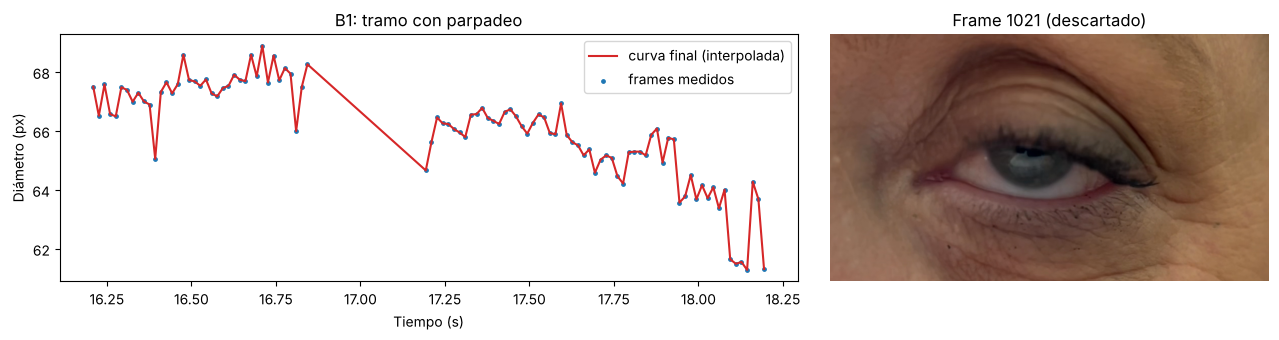

In [9]:
def segmentos_invalidos(df):
    inv = (~df["valido"]).astype(int).values
    bordes = np.diff(np.r_[0, inv, 0])
    ini, fin = np.where(bordes == 1)[0], np.where(bordes == -1)[0]
    return list(zip(ini, fin))

filas = []
for nombre, df in series.items():
    seg_inv = segmentos_invalidos(df)
    largos = [(f - i) for i, f in seg_inv]
    fps_r = 1 / df["tiempo_s"].diff().median()
    filas.append({"registro": nombre, "frames": len(df), "interpolados_%": round(100 * (~df["valido"]).mean(), 1),
                  "tramos_interpolados": len(seg_inv), "tramo_más_largo_s": round(max(largos) / fps_r, 2) if largos else 0,
                  "tramos_>0,1_s (parpadeo/oclusión)": sum(l / fps_r > 0.1 for l in largos)})
display(pd.DataFrame(filas).set_index("registro"))

# Ejemplo: parpadeo de B1 alrededor de los 17 s
if "B1" in series:
    df = series["B1"]; ruta = REGISTROS["B1"][0]
    sel = df[(df.tiempo_s > 16.2) & (df.tiempo_s < 18.2)]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [1.6, 1]})
    ax[0].plot(sel.tiempo_s, sel.diametro_px, "-", c="tab:red", label="curva final (interpolada)")
    ax[0].scatter(sel.tiempo_s[sel.valido], sel.diametro_px[sel.valido], s=6, c="tab:blue", label="frames medidos")
    ax[0].set_xlabel("Tiempo (s)"); ax[0].set_ylabel("Diámetro (px)"); ax[0].legend(); ax[0].set_title("B1: tramo con parpadeo")
    i_inv = sel.index[~sel.valido]
    if len(i_inv):
        fr = ev.leer_frame(ruta, int(i_inv[len(i_inv) // 2]))
        ax[1].imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Frame {int(i_inv[len(i_inv) // 2])} (descartado)"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

## 3.2 — Validación del diámetro y el área automáticos contra la medición manual (MAE/RMSE)
Se compara el diámetro (y el área) que mide el pipeline en cada frame anotado con la medición manual (`anotaciones/anotaciones_manuales.csv`, ver Módulo 2).

,video,frame,nota,valido,d_manual_px,d_auto_px,error_d_px,A_manual_px,A_auto_px,error_A_%
0,A1,120,penumbra; velo gris del reflejo sobre la mitad...,True,76.50,74.93,-1.57,4596,4410,-4.1
1,A1,331,penumbra; velo gris del reflejo sobre la mitad...,True,75.50,74.84,-0.66,4477,4399,-1.7
2,A1,700,con luz; borde nitido,True,52.50,54.53,2.03,2165,2335,7.9
3,A1,1300,con luz; borde nitido,True,55.48,57.43,1.95,2417,2590,7.1
4,A2,118,penumbra; imagen desenfocada; borde poco definido,True,59.97,61.93,1.96,2824,3012,6.6
5,A2,1000,con luz; reflejo corneal arriba,True,56.50,62.54,6.04,2507,3072,22.5
6,B1,200,con luz; reflejo corneal arriba a la izquierda,True,52.99,55.58,2.59,2205,2426,10.0
7,B1,1000,penumbra; velo gris arriba a la izquierda dent...,True,65.99,68.59,2.60,3420,3695,8.0


DIÁMETRO -> MAE = 2.42 px (4.1 %) | RMSE = 2.84 px | sesgo = +1.87 px
ÁREA     -> MAE = 232 px² (8.5 %) | RMSE = 269 px² | sesgo = +166 px²
Diámetro sin el frame A2/1000 -> MAE = 1.91 px | RMSE = 2.00 px


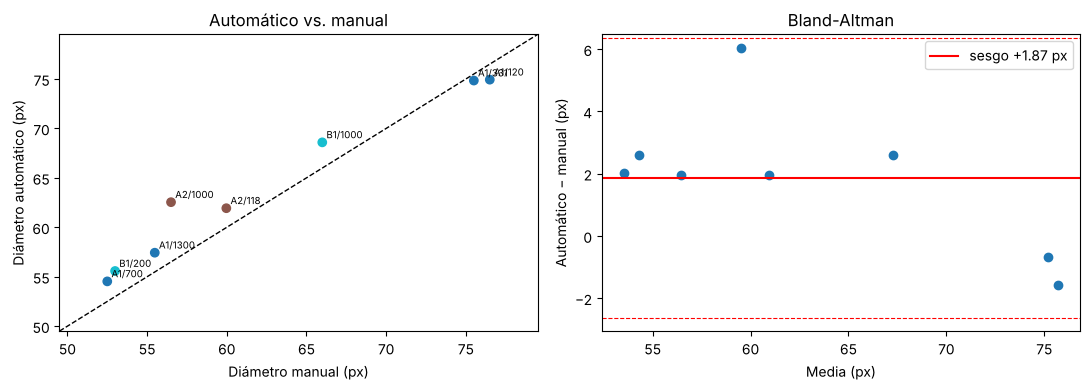

In [10]:
anot = ev.cargar_anotaciones()
filas = []
for _, f in anot.iterrows():
    if f.video not in series: continue
    s = series[f.video].loc[f.frame]
    filas.append({"video": f.video, "frame": f.frame, "nota": f.nota, "valido": bool(s["valido"]),
                  "d_manual_px": round(f.diametro_manual_px, 2), "d_auto_px": round(s["diametro_px"], 2),
                  "error_d_px": round(s["diametro_px"] - f.diametro_manual_px, 2),
                  "A_manual_px": round(f.area_manual_px), "A_auto_px": round(s["area_px"]),
                  "error_A_%": round(100 * (s["area_px"] - f.area_manual_px) / f.area_manual_px, 1)})
val = pd.DataFrame(filas)
display(val)

e_d = ev.errores_diametro(val.d_auto_px, val.d_manual_px)
e_a = ev.errores_diametro(val.A_auto_px, val.A_manual_px)
print(f"DIÁMETRO -> MAE = {e_d['MAE_px']:.2f} px ({e_d['MAE_%']:.1f} %) | RMSE = {e_d['RMSE_px']:.2f} px | sesgo = {e_d['sesgo_px']:+.2f} px")
print(f"ÁREA     -> MAE = {e_a['MAE_px']:.0f} px² ({e_a['MAE_%']:.1f} %) | RMSE = {e_a['RMSE_px']:.0f} px² | sesgo = {e_a['sesgo_px']:+.0f} px²")
sin_a2 = val[~((val.video == "A2") & (val.frame == 1000))]
e2 = ev.errores_diametro(sin_a2.d_auto_px, sin_a2.d_manual_px)
print(f"Diámetro sin el frame A2/1000 -> MAE = {e2['MAE_px']:.2f} px | RMSE = {e2['RMSE_px']:.2f} px")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(val.d_manual_px, val.d_auto_px, c=pd.factorize(val.video)[0], cmap="tab10")
for _, r in val.iterrows(): ax[0].annotate(f"{r.video}/{r.frame}", (r.d_manual_px, r.d_auto_px), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [val[["d_manual_px", "d_auto_px"]].min().min() - 3, val[["d_manual_px", "d_auto_px"]].max().max() + 3]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("Diámetro manual (px)"); ax[0].set_ylabel("Diámetro automático (px)"); ax[0].set_title("Automático vs. manual")
media = (val.d_manual_px + val.d_auto_px) / 2
ax[1].scatter(media, val.error_d_px); ax[1].axhline(val.error_d_px.mean(), c="r", label=f"sesgo {val.error_d_px.mean():+.2f} px")
sd = val.error_d_px.std(ddof=1)
for k in (-1.96, 1.96): ax[1].axhline(val.error_d_px.mean() + k * sd, c="r", ls="--", lw=.8)
ax[1].set_xlabel("Media (px)"); ax[1].set_ylabel("Automático − manual (px)"); ax[1].set_title("Bland-Altman"); ax[1].legend()
plt.tight_layout(); plt.show()

**Resultado de la validación (8 frames, 3 registros).**
- **Diámetro: MAE = 2,42 px (4,1 %), RMSE = 2,84 px.** Sin el frame A2/1000: **MAE = 1,91 px y RMSE = 2,00 px**.
- **Área: MAE ≈ 8,5 %.** El error relativo en el área es aproximadamente el doble que en el diámetro, porque A ∝ D².
- **Sesgo de +1,9 px:** el pipeline tiende a medir la pupila algo más grande. El sesgo cambia de signo según la condición:
  - En **penumbra con el velo del reflejo** (A1, frames 120 y 331) **subestima** entre 0,7 y 1,6 px, porque la elipse sobre el borde visible no recupera del todo la parte tapada.
  - **Con luz** sobrestima unos 2 px: la watershed ubica el borde en el máximo del gradiente, apenas por fuera de donde el ojo percibe el límite de la zona oscura en un borde algo difuso.
- **El peor caso es A2/1000** (+6 px): un frame con luz y una franja oscura del iris pegada a la pupila, que la segmentación incluye.
- **Impacto en los parámetros:** en A1 el basal se subestima un poco y el extremo se sobrestima, así que la amplitud automática (22,0 px) queda unos 1,5 px por debajo de la manual (≈ 23,5 px). Es un error de alrededor del 6 % en la amplitud, del mismo orden que la incertidumbre de la propia anotación manual (±1–2 px por borde).

**Limitaciones:** son pocos frames anotados (8) y por un solo anotador, y la referencia es una elipse por 4 extremos. Para una validación más robusta convendría anotar más frames, con más de un observador, y marcar el contorno completo.